## Setup and Imports

In [6]:
# Title: Imports

import sys
from pathlib import Path

# Add parent directory to path for imports
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import laspy
import numpy as np
import pandas as pd
from pyntcloud import PyntCloud
import matplotlib.pyplot as plt

from lidar_preprocessing import PreprocessingConfig, process_las, batch_process

print(f"✅ Project root: {PROJECT_ROOT}")
print("✅ Imports successful (including lidar_preprocessing)")

✅ Project root: /home/nvidia/projects/fvc_structure/phase_5_3d_cnn_training
✅ Imports successful (including lidar_preprocessing)


## Configuration

In [7]:
# Title: Input directory containing LAS files with structure + treeID (PLY-only, no NPZ)

from pathlib import Path

# Input directory containing LAS files with structure + treeID
INPUT_DIR = Path("/data/calperumResearch/site1_1_DD0001/lidar/clipped/3d_structure_mask_malleid")

# Output directories
OUT_PLY_DIR = Path("/data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/forestformer3d_ply/")

OUT_PLY_DIR.mkdir(parents=True, exist_ok=True)

# Processing parameters
VOXEL_SIZE = 0.10  # 10 cm voxels
IGNORE_INDEX = -100  # PyTorch convention for ignored labels

# Class mapping: LAS classification codes -> model class IDs
CLASS_REMAP = {
    64: 0,  # Forb
    65: 1,  # Woody debris
    66: 2,  # Hummock
    67: 3,  # Shrub
    68: 4,  # Mallee
    0: IGNORE_INDEX,  # Unmatched / background
}

config = PreprocessingConfig(
    input_dir=INPUT_DIR,
    out_ply_dir=OUT_PLY_DIR,
    voxel_size=VOXEL_SIZE,
    ignore_index=IGNORE_INDEX,
    class_remap=CLASS_REMAP,
    save_npz=False,
    out_npz_dir=None,
    ply_use_local_coords=True,
 )

print(config)

PreprocessingConfig(
  input_dir=/data/calperumResearch/site1_1_DD0001/lidar/clipped/3d_structure_mask_malleid,
  out_npz_dir=None,
  out_ply_dir=/data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/forestformer3d_ply,
  save_npz=False,
  ply_use_local_coords=True,
  save_ply_offset=True,
  voxel_size=0.1,
  num_classes=5,
  ignore_index=-100
)


## Preprocessing Functions

In [8]:
# Title: Preprocessing Functions (from lidar_preprocessing)

from lidar_preprocessing import (
    normalise_intensity,
    get_z_norm,
    remap_classes,
    get_tree_ids,
    write_forestformer_ply,
    process_las,
    batch_process,
)

print("✅ Using preprocessing functions from lidar_preprocessing")

✅ Using preprocessing functions from lidar_preprocessing


## Main Processing Function

In [9]:
# Title: Main Processing Function (from lidar_preprocessing)

# `process_las` and `batch_process` come from the lidar_preprocessing package.
# Implementation: phase_5_3d_cnn_training/lidar_preprocessing/preprocessing.py
print("✅ process_las/batch_process imported")

✅ process_las/batch_process imported


In [10]:
# Title: Run — Process one sample LAS

from pathlib import Path

# Pick one LAS
sample_las = Path(
    "/data/calperumResearch/site1_1_DD0001/lidar/clipped/3d_structure_mask_malleid/znorm_3Dlabels_106.las"
 )

npz_path, ply_path = process_las(sample_las, config)

print("NPZ:", npz_path)
print("PLY:", ply_path)

📦 Processing znorm_3Dlabels_106.las
NPZ: None
PLY: /data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/forestformer3d_ply/znorm_3Dlabels_106.ply


## Batch Processing

In [11]:
# Title: Discover — List LAS files

las_files = sorted(config.input_dir.glob("*.las"))

if not las_files:
    print(f"❌ No LAS files found in {config.input_dir}")
else:
    print(f"🚀 Found {len(las_files)} LAS files in {config.input_dir}.")
    print("\nFirst 5 files:")
    for f in las_files[:5]:
        print(f"   {f.name}")

🚀 Found 15 LAS files in /data/calperumResearch/site1_1_DD0001/lidar/clipped/3d_structure_mask_malleid.

First 5 files:
   znorm_3Dlabels_106.las
   znorm_3Dlabels_109.las
   znorm_3Dlabels_113.las
   znorm_3Dlabels_121.las
   znorm_3Dlabels_16.las


In [12]:
# Title: Run — Batch preprocess (lidar_preprocessing)

all_npz, all_ply, errors = batch_process(config, file_pattern="*.las")

if errors:
    print("\n⚠️ Errors encountered:")
    for fname, err in errors[:20]:
        print(f"  {fname}: {err}")
    if len(errors) > 20:
        print(f"  ... and {len(errors) - 20} more")

🚀 Found 15 LAS files.
📦 Processing znorm_3Dlabels_106.las
📦 Processing znorm_3Dlabels_109.las
📦 Processing znorm_3Dlabels_113.las


📦 Processing znorm_3Dlabels_121.las
📦 Processing znorm_3Dlabels_16.las
📦 Processing znorm_3Dlabels_182.las
📦 Processing znorm_3Dlabels_192.las
📦 Processing znorm_3Dlabels_205.las
📦 Processing znorm_3Dlabels_22.las
📦 Processing znorm_3Dlabels_26.las
📦 Processing znorm_3Dlabels_55.las
📦 Processing znorm_3Dlabels_65.las
📦 Processing znorm_3Dlabels_71.las
📦 Processing znorm_3Dlabels_93.las
📦 Processing znorm_3Dlabels_96.las

✅ Processing complete!
   Successful: 15 PLY files
   Errors: 0 files
📄 PLY list: /data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/forestformer3d_ply/ply_list.txt


## Validation: Inspect PLY Output (ForestFormer3D)

In [13]:
# Title: Load and inspect a sample PLY file

# Load and inspect a sample PLY file
if all_ply:
    sample_ply = Path(all_ply[0])
    print(f"📂 Inspecting: {sample_ply.name}\n")
    
    cloud = PyntCloud.from_file(str(sample_ply))
    df_ply = cloud.points
    
    print(f"Total points: {len(df_ply):,}")
    print(f"Columns: {df_ply.columns.tolist()}\n")
    
    print("Sample rows:\n")
    print(df_ply.head(10))
    
    print(f"\nData types:")
    print(df_ply.dtypes)
    
    print(f"\nValue ranges:")
    print(f"  X: [{df_ply['x'].min():.2f}, {df_ply['x'].max():.2f}]")
    print(f"  Y: [{df_ply['y'].min():.2f}, {df_ply['y'].max():.2f}]")
    print(f"  Z: [{df_ply['z'].min():.2f}, {df_ply['z'].max():.2f}]")
    print(f"  z_norm: [{df_ply['z_norm'].min():.2f}, {df_ply['z_norm'].max():.2f}]")
    print(f"  intensity: [{df_ply['intensity'].min():.3f}, {df_ply['intensity'].max():.3f}]")
    
    print(f"\nClass distribution:")
    print(df_ply['semantic_seg'].value_counts().sort_index())

📂 Inspecting: znorm_3Dlabels_106.ply

Total points: 265,746
Columns: ['x', 'y', 'z', 'semantic_seg', 'treeID', 'z_norm', 'intensity']

Sample rows:

           x     y     z  semantic_seg  treeID        z_norm  intensity
0  25.799999  0.05  0.68             2       0  0.000000e+00   0.231373
1  27.770000  0.01  0.72             2       0  4.471713e-07   0.176471
2  25.730000  0.13  0.70             2       0  1.816984e-02   0.231373
3  27.709999  0.06  0.71             2       0  4.471824e-07   0.172549
4  28.780001  0.00  0.76             2       0  1.210322e-02   0.235294
5  21.469999  0.03  0.66             4       0  2.288326e-02   0.145098
6  27.379999  0.09  0.70             2       0  7.105427e-15   0.168627
7  21.030001  0.01  1.12             4       0  4.930632e-01   0.113725
8  21.299999  0.04  0.68             4       0  5.033479e-02   0.152941
9  28.750000  0.09  0.75             2       0  6.324155e-07   0.231373

Data types:
x               float32
y               float3

## Summary Statistics Across All Files

In [14]:
# Title: Aggregate statistics from all processed PLY files

# Aggregate statistics from all processed PLY files
from pathlib import Path

if all_ply:
    total_points = 0
    total_trees = set()
    class_counts_global = {}

    print("Analyzing all PLY files...\n")

    for ply_path in all_ply:
        ply_path = Path(ply_path)
        if not ply_path.exists():
            print(f"⚠️ Missing PLY: {ply_path}")
            continue

        df = PyntCloud.from_file(str(ply_path)).points
        n_pts = len(df)
        total_points += n_pts

        # Instance IDs (treeID)
        if "treeID" in df.columns:
            inst = df["treeID"].to_numpy(dtype=np.int32)
            total_trees.update(inst[inst > 0])
        else:
            inst = None

        # Semantic classes
        if "semantic_seg" in df.columns:
            sem = df["semantic_seg"].to_numpy(dtype=np.int32)
            unique, counts = np.unique(sem, return_counts=True)
            for cls, cnt in zip(unique, counts):
                class_counts_global[int(cls)] = class_counts_global.get(int(cls), 0) + int(cnt)
        else:
            print(f"⚠️ No 'semantic_seg' in {ply_path.name}, skipping class counts")

    print(f"📊 Dataset Statistics:")
    print(f"   Total files: {len(all_ply)}")
    print(f"   Total points: {total_points:,}")
    print(f"   Unique trees: {len(total_trees)}" if total_trees else "   Unique trees: (treeID not found)")

    if total_points > 0 and class_counts_global:
        print(f"\n   Global class distribution:")
        for cls in sorted(class_counts_global.keys()):
            cnt = class_counts_global[cls]
            pct = 100 * cnt / total_points
            if cls == IGNORE_INDEX:
                print(f"     {cls:3d} (IGNORE): {cnt:>12,} ({pct:5.2f}%)")
            else:
                print(f"     {cls:3d}         : {cnt:>12,} ({pct:5.2f}%)")
    else:
        print("\n   (No class stats computed; check that PLYs exist and contain 'semantic_seg'.)")
else:
    print("❌ No PLY files to analyze. Run the batch processing cell first.")

Analyzing all PLY files...



📊 Dataset Statistics:
   Total files: 15
   Total points: 7,953,134
   Unique trees: 78

   Global class distribution:
       2         :    1,326,682 (16.68%)
       3         :      313,680 ( 3.94%)
       4         :    6,312,772 (79.37%)


## Visualization: Class Distribution

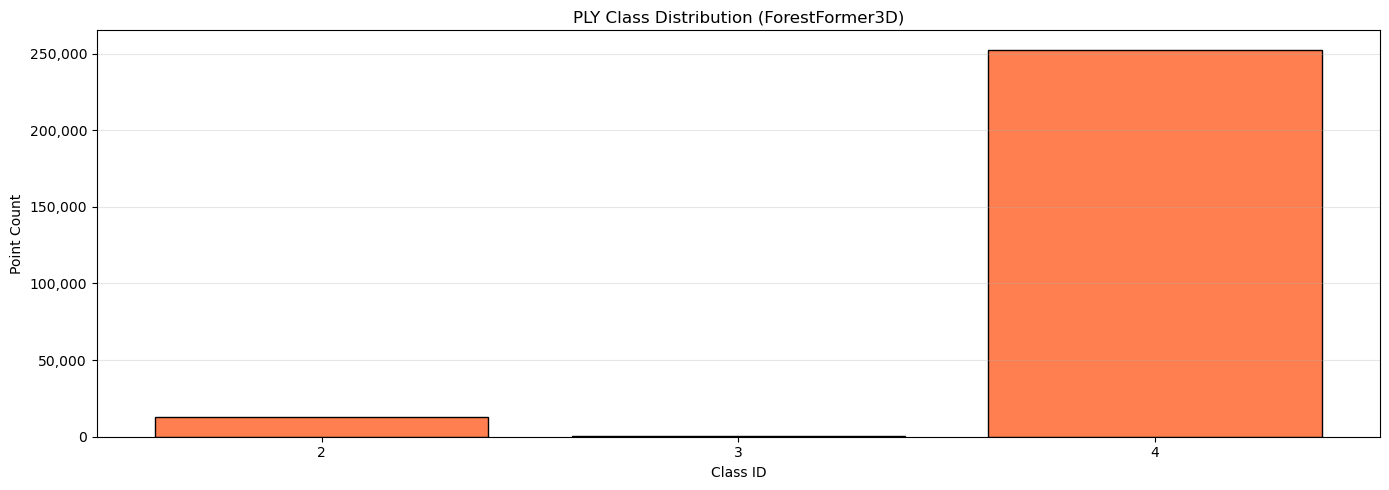


Class distribution (sample PLY):
    2:       12,585  ( 4.74%)
    3:          604  ( 0.23%)
    4:      252,557  (95.04%)

✅ Both formats should show identical class distributions
   (NPZ includes IGNORE_INDEX points, PLY excludes them)


In [15]:
# Title: Code: if all_ply:

if all_ply:
    from pathlib import Path
    import matplotlib.ticker as mticker

    # Ensure we have a dataframe to plot from (load first PLY if needed)
    if "df_ply" not in globals() or df_ply is None or len(df_ply) == 0:
        sample_ply = Path(all_ply[0])
        df_ply = PyntCloud.from_file(str(sample_ply)).points
        print(f"📂 Loaded sample for plotting: {sample_ply.name} ({len(df_ply):,} points)")

    # Class distribution from PLY (sample)
    class_counts = df_ply["semantic_seg"].value_counts().sort_index()

    fig, ax = plt.subplots(1, 1, figsize=(14, 5))
    ax.bar(class_counts.index.astype(int), class_counts.values, color="coral", edgecolor="black")
    ax.set_xlabel("Class ID")
    ax.set_ylabel("Point Count")
    ax.set_title("PLY Class Distribution (ForestFormer3D)")
    ax.grid(True, alpha=0.3, axis="y")

    # Make x-axis show integer class IDs cleanly
    ax.set_xticks(class_counts.index.astype(int))
    ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))

    # Make y-axis easier to read
    ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))

    plt.tight_layout()
    plt.show()

    # Print counts + percentages (sample)
    total = int(class_counts.sum())
    print("\nClass distribution (sample PLY):")
    for cls_id, cnt in class_counts.items():
        pct = 100.0 * float(cnt) / float(total) if total else 0.0
        print(f"  {int(cls_id):>3d}: {int(cnt):>12,}  ({pct:5.2f}%)")

    print("\n✅ Both formats should show identical class distributions")
    print("   (NPZ includes IGNORE_INDEX points, PLY excludes them)")
else:
    print("❌ No PLY files available. Run the batch processing cell first.")

In [16]:
# Title: Imports

import numpy as np
import laspy
from pyntcloud import PyntCloud

def check_las(las_path):
    las = laspy.read(str(las_path))
    xyz = np.c_[las.x, las.y, las.z]
    print("LAS:", las_path)
    print("  XYZ min:", xyz.min(axis=0))
    print("  XYZ max:", xyz.max(axis=0))
    print("  XYZ range:", xyz.max(axis=0) - xyz.min(axis=0))
    print("  Z std:", xyz[:,2].std())

def check_ply(ply_path):
    df = PyntCloud.from_file(str(ply_path)).points
    xyz = df[["x","y","z"]].to_numpy(float)
    print("PLY:", ply_path)
    print("  XYZ min:", xyz.min(axis=0))
    print("  XYZ max:", xyz.max(axis=0))
    print("  XYZ range:", xyz.max(axis=0) - xyz.min(axis=0))
    print("  Z std:", xyz[:,2].std())
    if "z_norm" in df.columns:
        zn = df["z_norm"].to_numpy(float)
        print("  z_norm range:", (zn.min(), zn.max()))

from pathlib import Path

# --- set paths (edit if needed) ---
las_orig = Path("/data/calperumResearch/site1_1_DD0001/lidar/clipped/3d_structure_mask_malleid/znorm_3Dlabels_106.las")


las_from_ply = Path("/data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/reconstructed_las/znorm_3Dlabels_106_from_ply.las")

ply_in = Path("/data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/forestformer3d_ply/znorm_3Dlabels_106.ply")

# --- run checks ---
if las_orig.exists():
    check_las(las_orig)


if las_from_ply.exists():
    check_las(las_from_ply)

if ply_in.exists():
    check_ply(ply_in)

LAS: /data/calperumResearch/site1_1_DD0001/lidar/clipped/3d_structure_mask_malleid/znorm_3Dlabels_106.las
  XYZ min: [4.6167947e+05 6.2375062e+06 5.7830000e+01]
  XYZ max: [4.6171017e+05 6.2375369e+06 6.2750000e+01]
  XYZ range: [30.7  30.7   4.92]
  Z std: 0.8590239936444897
LAS: /data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/reconstructed_las/znorm_3Dlabels_106_from_ply.las
  XYZ min: [4.6167947e+05 6.2375062e+06 5.7830000e+01]
  XYZ max: [4.6171017e+05 6.2375369e+06 6.2750000e+01]
  XYZ range: [30.7  30.7   4.92]
  Z std: 0.859190818109963
PLY: /data/calperumResearch/site1_1_DD0001/lidar/clipped/preprocessed/forestformer3d_ply/znorm_3Dlabels_106.ply
  XYZ min: [0. 0. 0.]
  XYZ max: [30.70000076 30.70000076  4.92000008]
  XYZ range: [30.70000076 30.70000076  4.92000008]
  Z std: 0.8590239934514342
  z_norm range: (0.0, 4.419999122619629)
